In [1]:
import os
import gzip
import struct
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [9]:
DATA_DIR = "."

def load_images(filename):
    path = os.path.join(DATA_DIR, filename)

    opener = gzip.open if filename.endswith(".gz") else open

    with opener(path, "rb") as file:
        magic, count, rows, cols = struct.unpack(">IIII", file.read(16))
        images = np.frombuffer(file.read(), dtype=np.uint8)

    if magic != 2051:
        raise ValueError(f"Неверный формат изображений: {filename}")

    return images.reshape(count, rows, cols)


def load_labels(filename):
    path = os.path.join(DATA_DIR, filename)

    opener = gzip.open if filename.endswith(".gz") else open

    with opener(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        labels = np.frombuffer(file.read(), dtype=np.uint8)

    if magic != 2049:
        raise ValueError(f"Неверный формат меток: {filename}")

    return labels


X_train_images = load_images("train-images.idx3-ubyte")
y_train = load_labels("train-labels.idx1-ubyte")

X_test_images = load_images("t10k-images.idx3-ubyte")
y_test = load_labels("t10k-labels.idx1-ubyte")

print("Размер обучающей выборки:", X_train_images.shape)
print("Размер меток обучения:", y_train.shape)
print("Размер тестовой выборки:", X_test_images.shape)
print("Размер тестовых меток:", y_test.shape)
print("Форма одного изображения:", X_train_images[0].shape)

Размер обучающей выборки: (60000, 28, 28)
Размер меток обучения: (60000,)
Размер тестовой выборки: (10000, 28, 28)
Размер тестовых меток: (10000,)
Форма одного изображения: (28, 28)


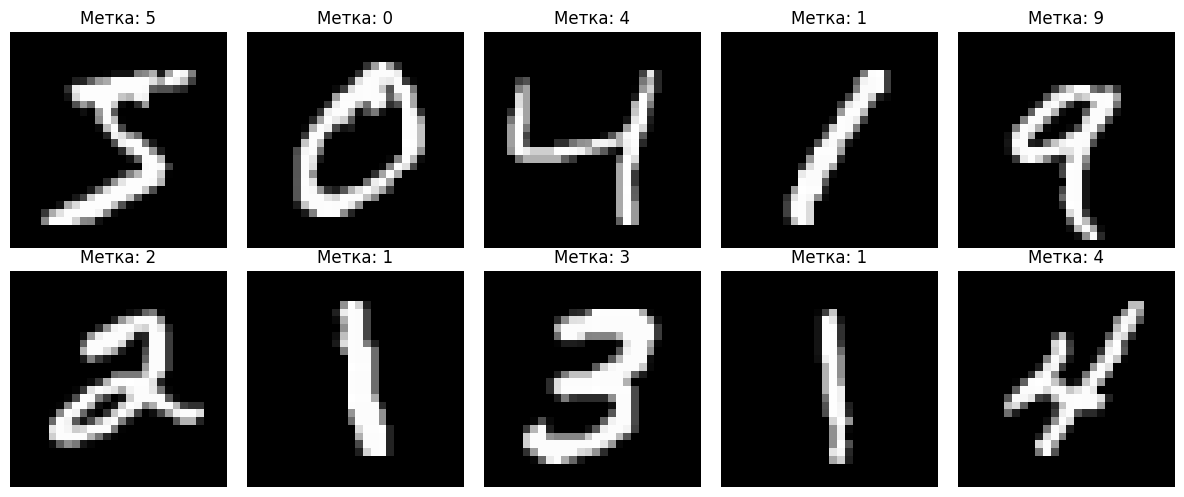

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for index, axis in enumerate(axes.flat):
    axis.imshow(X_train_images[index], cmap="gray")
    axis.set_title(f"Метка: {y_train[index]}")
    axis.axis("off")

plt.tight_layout()
plt.show()

In [11]:
X_train = X_train_images.reshape(-1, 784).astype(np.float32) / 255.0
X_test = X_test_images.reshape(-1, 784).astype(np.float32) / 255.0

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (60000, 784)
X_test: (10000, 784)


In [13]:
class NeuralNetwork:
    def __init__(self, input_size=784, hidden_size=300, output_size=10):
        self.W1 = (
            np.random.randn(input_size, hidden_size)
            * np.sqrt(2.0 / input_size)
        ).astype(np.float32)

        self.b1 = np.zeros((1, hidden_size), dtype=np.float32)

        self.W2 = (
            np.random.randn(hidden_size, output_size)
            * np.sqrt(2.0 / hidden_size)
        ).astype(np.float32)

        self.b2 = np.zeros((1, output_size), dtype=np.float32)

    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.H = np.maximum(0, self.Z1)

        self.Z2 = self.H @ self.W2 + self.b2
        shifted = self.Z2 - np.max(self.Z2, axis=1, keepdims=True)

        exp_values = np.exp(shifted)
        self.P = exp_values / np.sum(exp_values, axis=1, keepdims=True)

        return self.P

    def backward(self, X, y):
        batch_size = X.shape[0]

        delta2 = self.P.copy()
        delta2[np.arange(batch_size), y] -= 1
        delta2 /= batch_size

        dW2 = self.H.T @ delta2
        db2 = np.sum(delta2, axis=0, keepdims=True)

        delta1 = (delta2 @ self.W2.T) * (self.Z1 > 0)

        dW1 = X.T @ delta1
        db1 = np.sum(delta1, axis=0, keepdims=True)

        return dW1, db1, dW2, db2

    def update(self, gradients, learning_rate):
        dW1, db1, dW2, db2 = gradients

        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2

    def predict(self, X, batch_size=1000):
        predictions = []

        for start in range(0, len(X), batch_size):
            probabilities = self.forward(X[start:start + batch_size])
            predictions.append(np.argmax(probabilities, axis=1))

        return np.concatenate(predictions)

    def loss(self, X, y, batch_size=1000):
        total_loss = 0.0

        for start in range(0, len(X), batch_size):
            batch_X = X[start:start + batch_size]
            batch_y = y[start:start + batch_size]

            probabilities = self.forward(batch_X)
            correct_probabilities = probabilities[
                np.arange(len(batch_y)), batch_y
            ]

            total_loss -= np.sum(np.log(np.maximum(
                correct_probabilities, 1e-12
            )))

        return total_loss / len(X)

    def accuracy(self, X, y):
        predictions = self.predict(X)
        return np.mean(predictions == y)

In [14]:
hidden_size = 300
learning_rate = 0.1
batch_size = 64
epochs = 20

model = NeuralNetwork(hidden_size=hidden_size)

epoch_losses = []
epoch_accuracies = []
epoch_times = []

for epoch in range(epochs):
    start_time = time.time()

    permutation = np.random.permutation(len(X_train))

    for start in range(0, len(X_train), batch_size):
        indices = permutation[start:start + batch_size]

        batch_X = X_train[indices]
        batch_y = y_train[indices]

        model.forward(batch_X)
        gradients = model.backward(batch_X, batch_y)
        model.update(gradients, learning_rate)

    train_loss = model.loss(X_train, y_train)
    train_accuracy = model.accuracy(X_train, y_train)
    elapsed_time = time.time() - start_time

    epoch_losses.append(train_loss)
    epoch_accuracies.append(train_accuracy)
    epoch_times.append(elapsed_time)

    print(
        f"Эпоха {epoch + 1:02d}/{epochs} | "
        f"Ошибка: {train_loss:.4f} | "
        f"Ошибка классификации: {1 - train_accuracy:.4%} | "
        f"Время: {elapsed_time:.2f} сек."
    )

Эпоха 01/20 | Ошибка: 0.2290 | Ошибка классификации: 6.4100% | Время: 0.85 сек.
Эпоха 02/20 | Ошибка: 0.1516 | Ошибка классификации: 4.2783% | Время: 0.75 сек.
Эпоха 03/20 | Ошибка: 0.1166 | Ошибка классификации: 3.2100% | Время: 0.75 сек.
Эпоха 04/20 | Ошибка: 0.0936 | Ошибка классификации: 2.5633% | Время: 0.75 сек.
Эпоха 05/20 | Ошибка: 0.0854 | Ошибка классификации: 2.3917% | Время: 0.76 сек.
Эпоха 06/20 | Ошибка: 0.0683 | Ошибка классификации: 1.8367% | Время: 0.78 сек.
Эпоха 07/20 | Ошибка: 0.0609 | Ошибка классификации: 1.6133% | Время: 0.76 сек.
Эпоха 08/20 | Ошибка: 0.0543 | Ошибка классификации: 1.3800% | Время: 0.75 сек.
Эпоха 09/20 | Ошибка: 0.0465 | Ошибка классификации: 1.1550% | Время: 0.75 сек.
Эпоха 10/20 | Ошибка: 0.0425 | Ошибка классификации: 1.0817% | Время: 0.75 сек.
Эпоха 11/20 | Ошибка: 0.0365 | Ошибка классификации: 0.8667% | Время: 0.76 сек.
Эпоха 12/20 | Ошибка: 0.0344 | Ошибка классификации: 0.8350% | Время: 0.77 сек.
Эпоха 13/20 | Ошибка: 0.0295 | Ошибка кл

In [15]:
test_predictions = model.predict(X_test)

test_accuracy = np.mean(test_predictions == y_test)
test_error = 1.0 - test_accuracy

print(f"Точность на тестовой выборке: {test_accuracy:.2%}")
print(f"Ошибка классификации: {test_error:.2%}")

Точность на тестовой выборке: 97.98%
Ошибка классификации: 2.02%


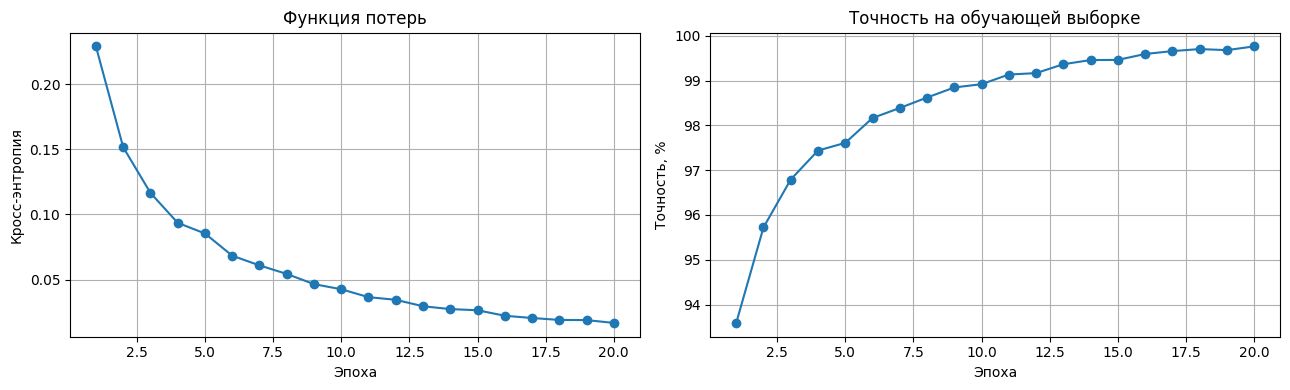

Суммарное время обучения: 15.51 сек.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(range(1, epochs + 1), epoch_losses, marker="o")
axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Кросс-энтропия")
axes[0].grid(True)

axes[1].plot(
    range(1, epochs + 1),
    np.array(epoch_accuracies) * 100,
    marker="o"
)
axes[1].set_title("Точность на обучающей выборке")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Точность, %")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Суммарное время обучения: {sum(epoch_times):.2f} сек.")

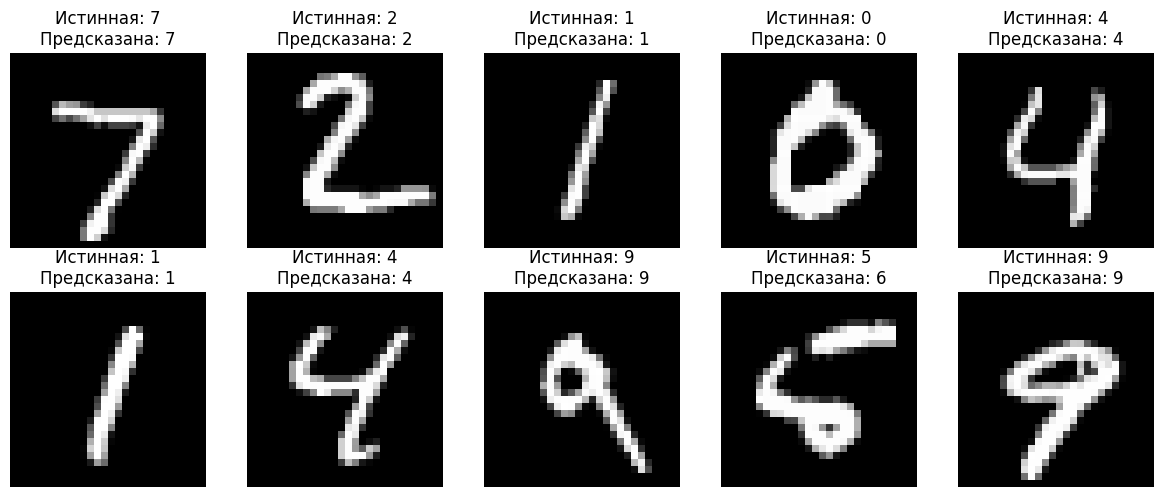

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for index, axis in enumerate(axes.flat):
    axis.imshow(X_test_images[index], cmap="gray")
    axis.set_title(
        f"Истинная: {y_test[index]}\n"
        f"Предсказана: {test_predictions[index]}"
    )
    axis.axis("off")

plt.tight_layout()
plt.show()